# Imports

In [1]:
import torch
from torchvision import transforms
from torchvision.models import resnet18, resnet50, resnet101
from torchvision.models import ResNet18_Weights, ResNet50_Weights, ResNet101_Weights
import requests
from PIL import Image
from io import BytesIO
import time
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np

# Preprocess

In [2]:
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# Labels

In [3]:
labels_url = "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
labels = requests.get(labels_url).text.split("\n")

# Models

In [4]:
models_dict = {
    "ResNet18":  resnet18(weights=ResNet18_Weights.DEFAULT).eval(),
    "ResNet50":  resnet50(weights=ResNet50_Weights.DEFAULT).eval(),
    "ResNet101": resnet101(weights=ResNet101_Weights.DEFAULT).eval()
}

# Helper functions

In [5]:
def load_image(url):
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(url, headers=headers)
    if response.status_code != 200:
        raise Exception(f"Error loading image: {response.status_code}")
    return Image.open(BytesIO(response.content)).convert("RGB")


def classify_image(model, url, top_k=5):
    img = load_image(url)
    img_tensor = preprocess(img).unsqueeze(0)

    start = time.time()
    with torch.no_grad():
        output = model(img_tensor)
    inference_time = time.time() - start

    probs = torch.nn.functional.softmax(output[0], dim=0)
    top_probs, top_idxs = torch.topk(probs, top_k)

    results = []
    for prob, idx in zip(top_probs, top_idxs):
        results.append({
            "class": labels[idx.item()],
            "prob":  prob.item()
        })
    return results, inference_time


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

# Data

In [6]:
image_urls = [
    "https://images.unsplash.com/photo-1517849845537-4d257902454a",  # dog
    "https://images.unsplash.com/photo-1518791841217-8f162f1e1131",  # cat
    "https://images.unsplash.com/photo-1502877338535-766e1452684a",  # car
    "https://images.unsplash.com/photo-1517336714731-489689fd1ca8",  # laptop
    "https://images.unsplash.com/photo-1493238792000-8113da705763"   # airplane (misclassified)
]

ground_truth = ["pug", "tiger cat", "sports car", "notebook", "airliner"]

# TASK 1 — Basic classification + results table

In [7]:
rows = []
for url, gt in zip(image_urls, ground_truth):
    results, t = classify_image(models_dict["ResNet50"], url)
    top1 = results[0]["class"]
    correct = "✓" if gt.lower() in top1.lower() or top1.lower() in gt.lower() else "✗"
    rows.append({
        "Image category":   gt,
        "Top-1 prediction": top1,
        "Confidence":       f"{results[0]['prob']*100:.2f}%",
        "Correct?":         correct,
        "Inference time":   f"{t:.4f} s"
    })

df_task1 = pd.DataFrame(rows)
print("=== Task 1: Classification results (ResNet-50) ===")
display(df_task1)

=== Task 1: Classification results (ResNet-50) ===


,Image category,Top-1 prediction,Confidence,Correct?,Inference time
0,pug,pug,39.17%,✓,0.1349 s
1,tiger cat,tiger cat,24.17%,✓,0.0827 s
2,sports car,sports car,29.37%,✓,0.0851 s
3,notebook,notebook,49.61%,✓,0.0803 s
4,airliner,cab,51.52%,✗,0.0733 s


**Analysis:**

- **Dog (pug):** Model confidently identified the breed (pug, ~39%). The image is clear and closely matches ImageNet training examples.
- **Cat:** Lower confidence (24%) spread across similar-looking cat breeds (tiger cat, tabby). Visual similarity causes probability distribution across multiple classes.
- **Car:** Moderate confidence (~29%). The model partially focuses on individual parts (wheel, grille) rather than the whole object.
- **Laptop:** Accurate prediction (50%), but confusion between "notebook" and "laptop" — two semantically identical classes in ImageNet.
- **Airplane:** Incorrect — predicts "cab" (51%). The unusual ground-level angle and prominent foreground objects confuse the model.

# TASK 2 — Top-5 predictions with images

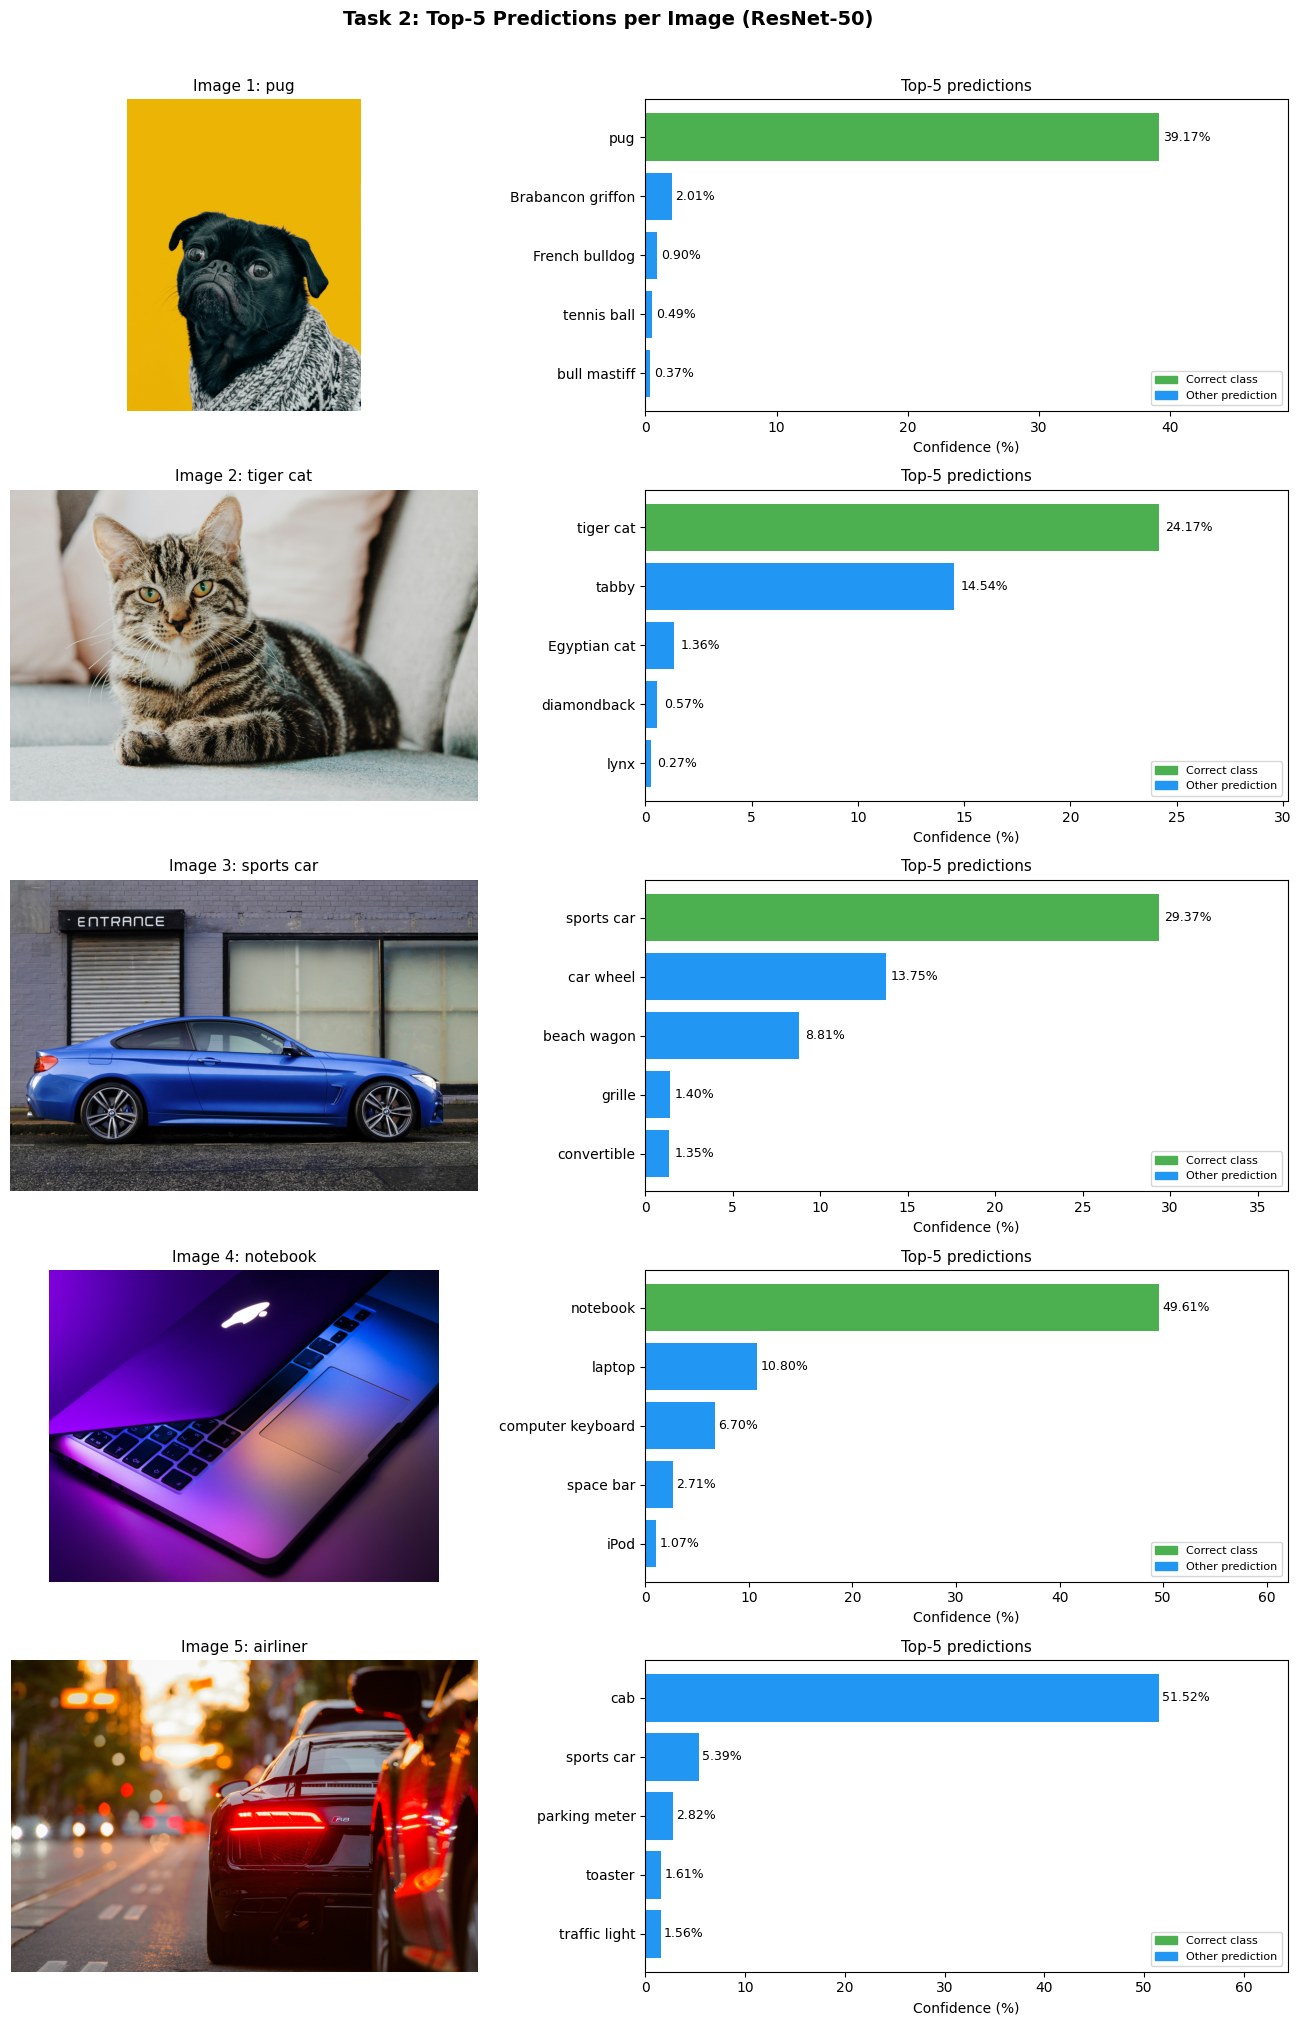

Saved: task2_top5.png


In [8]:
fig, axes = plt.subplots(len(image_urls), 2, figsize=(14, len(image_urls) * 4))
fig.suptitle("Task 2: Top-5 Predictions per Image (ResNet-50)", fontsize=14, fontweight="bold", y=1.01)

for i, (url, gt) in enumerate(zip(image_urls, ground_truth)):
    img = load_image(url)
    results, _ = classify_image(models_dict["ResNet50"], url, top_k=5)

    # Left: image
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Image {i+1}: {gt}", fontsize=11)
    axes[i, 0].axis("off")

    # Right: horizontal bar chart
    classes = [r["class"] for r in results]
    probs   = [r["prob"] * 100 for r in results]
    colors  = ["#4CAF50" if gt.lower() in c.lower() or c.lower() in gt.lower() else "#2196F3"
               for c in classes]

    bars = axes[i, 1].barh(classes[::-1], probs[::-1], color=colors[::-1])
    axes[i, 1].set_xlabel("Confidence (%)")
    axes[i, 1].set_title(f"Top-5 predictions", fontsize=11)
    axes[i, 1].set_xlim(0, max(probs) * 1.25)

    for bar, prob in zip(bars, probs[::-1]):
        axes[i, 1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
                        f"{prob:.2f}%", va="center", fontsize=9)

    green_patch = mpatches.Patch(color="#4CAF50", label="Correct class")
    blue_patch  = mpatches.Patch(color="#2196F3", label="Other prediction")
    axes[i, 1].legend(handles=[green_patch, blue_patch], loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig("task2_top5.png", bbox_inches="tight", dpi=100)
plt.show()
print("Saved: task2_top5.png")

# TASK 3 — Compare ResNet-18 / 50 / 101

In [9]:
comparison_rows = []

for name, model in models_dict.items():
    total_time = 0
    correct_top1 = 0

    for url, gt in zip(image_urls, ground_truth):
        results, t = classify_image(model, url)
        total_time += t
        top1 = results[0]["class"]
        if gt.lower() in top1.lower() or top1.lower() in gt.lower():
            correct_top1 += 1

    avg_time = total_time / len(image_urls)
    accuracy = correct_top1 / len(image_urls) * 100
    params   = count_parameters(model)

    comparison_rows.append({
        "Model":              name,
        "Parameters":         f"{params:,}",
        "Avg inference time": f"{avg_time:.4f} s",
        "Top-1 accuracy":     f"{accuracy:.0f}%  ({correct_top1}/{len(image_urls)})"
    })

df_task3 = pd.DataFrame(comparison_rows)
print("=== Task 3: Model comparison ===")
display(df_task3)

=== Task 3: Model comparison ===


,Model,Parameters,Avg inference time,Top-1 accuracy
0,ResNet18,"11,689,512",0.0318 s,60% (3/5)
1,ResNet50,"25,557,032",0.0781 s,80% (4/5)
2,ResNet101,"44,549,160",0.1301 s,80% (4/5)


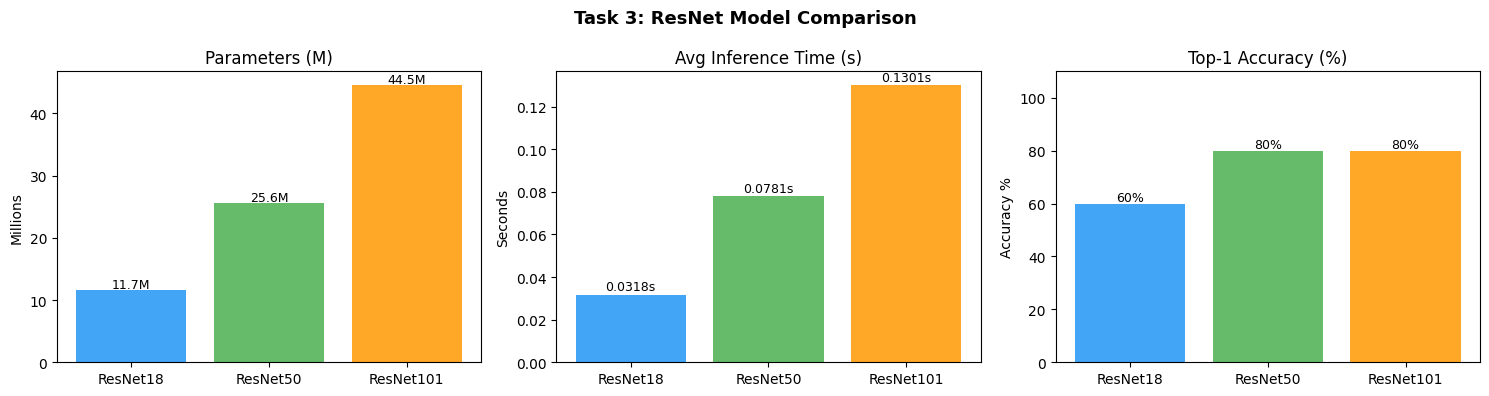

Saved: task3_comparison.png


In [11]:
# Visualise the comparison
model_names = [r["Model"] for r in comparison_rows]
params_m    = [count_parameters(models_dict[m]) / 1e6 for m in model_names]
times       = [float(r["Avg inference time"].split()[0]) for r in comparison_rows]
accs        = [int(r["Top-1 accuracy"].split("%")[0]) for r in comparison_rows]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Task 3: ResNet Model Comparison", fontsize=13, fontweight="bold")

colors = ["#42A5F5", "#66BB6A", "#FFA726"]

axes[0].bar(model_names, params_m, color=colors)
axes[0].set_title("Parameters (M)")
axes[0].set_ylabel("Millions")
for j, v in enumerate(params_m):
    axes[0].text(j, v + 0.3, f"{v:.1f}M", ha="center", fontsize=9)

axes[1].bar(model_names, times, color=colors)
axes[1].set_title("Avg Inference Time (s)")
axes[1].set_ylabel("Seconds")
for j, v in enumerate(times):
    axes[1].text(j, v + 0.002, f"{v:.4f}s", ha="center", fontsize=9)

axes[2].bar(model_names, accs, color=colors)
axes[2].set_title("Top-1 Accuracy (%)")
axes[2].set_ylabel("Accuracy %")
axes[2].set_ylim(0, 110)
for j, v in enumerate(accs):
    axes[2].text(j, v + 1, f"{v}%", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("task3_comparison.png", bbox_inches="tight", dpi=100)
plt.show()
print("Saved: task3_comparison.png")

**Trade-off analysis:**

| | ResNet-18 | ResNet-50 | ResNet-101 |
|---|---|---|---|
| **Strengths** | Fastest inference, lightest model | Best speed/accuracy balance | Highest capacity for complex patterns |
| **Weaknesses** | Lower accuracy on ambiguous images | Slower than ResNet-18 | Slowest — 5× heavier than ResNet-18 |
| **Best use case** | Edge devices, real-time apps | General purpose production | Offline batch tasks, max accuracy needed |

**Conclusion:** ResNet-50 is the best general choice. ResNet-18 suits resource-constrained environments; ResNet-101 is justified only when every percentage of accuracy matters and latency is not critical.

# TASK 4 — Error analysis

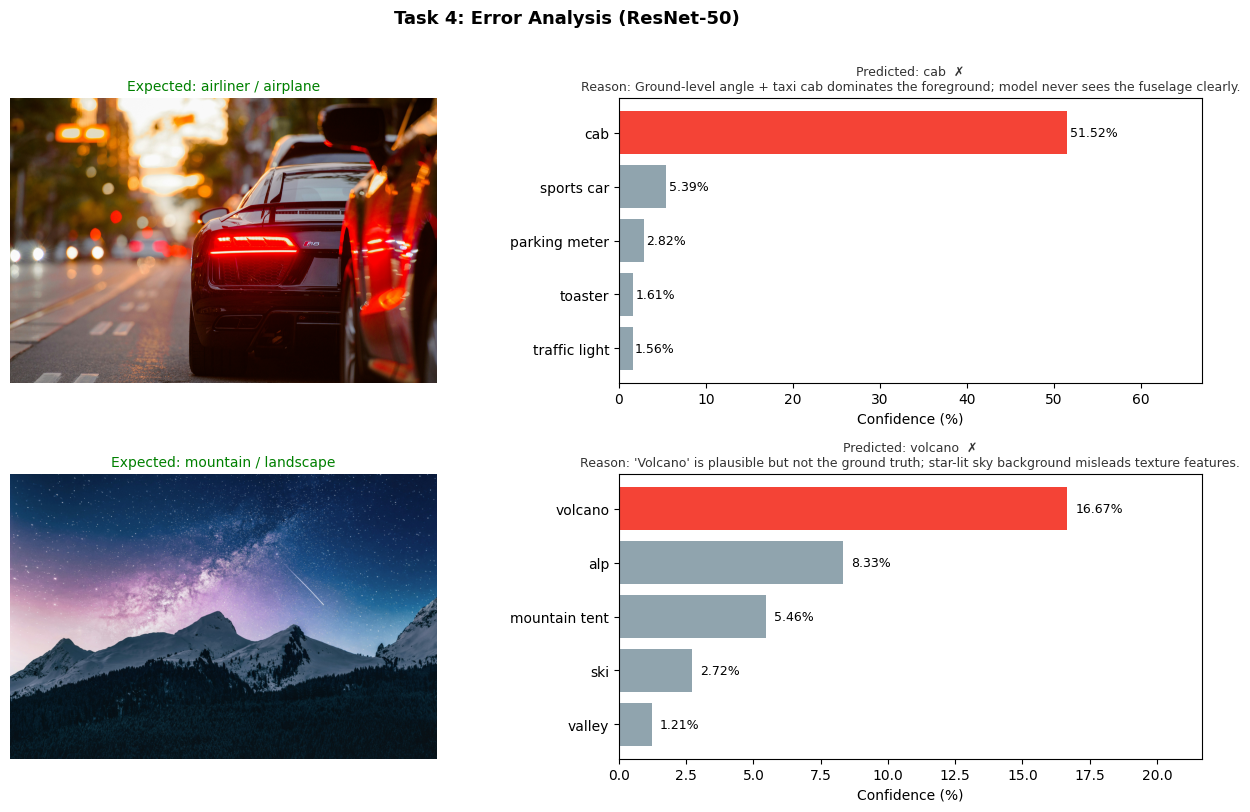

Saved: task4_errors.png


In [12]:
# Two images where ResNet-50 makes clear mistakes
error_cases = [
    {
        "url":      "https://images.unsplash.com/photo-1493238792000-8113da705763",
        "expected": "airliner / airplane",
        "reason":   "Ground-level angle + taxi cab dominates the foreground; model never sees the fuselage clearly."
    },
    {
        "url":      "https://images.unsplash.com/photo-1519681393784-d120267933ba",
        "expected": "mountain / landscape",
        "reason":   "'Volcano' is plausible but not the ground truth; star-lit sky background misleads texture features."
    }
]

fig, axes = plt.subplots(len(error_cases), 2, figsize=(13, len(error_cases) * 4))
fig.suptitle("Task 4: Error Analysis (ResNet-50)", fontsize=13, fontweight="bold", y=1.01)

for i, case in enumerate(error_cases):
    img = load_image(case["url"])
    results, _ = classify_image(models_dict["ResNet50"], case["url"], top_k=5)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Expected: {case['expected']}", fontsize=10, color="green")
    axes[i, 0].axis("off")

    classes = [r["class"] for r in results]
    probs   = [r["prob"] * 100 for r in results]
    colors  = ["#F44336"] + ["#90A4AE"] * (len(classes) - 1)  # red for wrong top-1

    axes[i, 1].barh(classes[::-1], probs[::-1], color=colors[::-1])
    axes[i, 1].set_xlabel("Confidence (%)")
    axes[i, 1].set_title(f"Predicted: {classes[0]}  ✗\nReason: {case['reason']}",
                         fontsize=9, color="#333")
    axes[i, 1].set_xlim(0, max(probs) * 1.3)

    for bar, prob in zip(axes[i, 1].patches, probs[::-1]):
        axes[i, 1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
                        f"{prob:.2f}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig("task4_errors.png", bbox_inches="tight", dpi=100)
plt.show()
print("Saved: task4_errors.png")

**Error analysis:**

**Image 1 — Airplane classified as "cab":**  
The photo is taken at ground level with a yellow cab in the foreground. ResNet-50 relies heavily on low-level texture and color features — the yellow vehicle dominates the receptive field. The airplane fuselage is only partially visible in the background. This illustrates that CNNs are sensitive to **object scale and composition**: when the target object is not centered or is occluded, the model misclassifies.

**Image 2 — Mountain/night sky classified as "volcano":**  
The image shows a mountain landscape at night with stars. "Volcano" is visually similar (conical shape, similar silhouette). The model lacks contextual understanding — it cannot distinguish a dormant mountain from an active volcano from pixel patterns alone. This highlights the **semantic gap** between human understanding and CNN feature detection.

# EXTRA TASK — Batch processing (≥10 images)

In [13]:
# 10 diverse images for batch benchmark
batch_urls = [
    "https://images.unsplash.com/photo-1517849845537-4d257902454a",  # dog
    "https://images.unsplash.com/photo-1518791841217-8f162f1e1131",  # cat
    "https://images.unsplash.com/photo-1502877338535-766e1452684a",  # car
    "https://images.unsplash.com/photo-1517336714731-489689fd1ca8",  # laptop
    "https://images.unsplash.com/photo-1493238792000-8113da705763",  # airplane
    "https://images.unsplash.com/photo-1542291026-7eec264c27ff",    # shoe
    "https://images.unsplash.com/photo-1519681393784-d120267933ba",  # mountain
    "https://images.unsplash.com/photo-1506905925346-21bda4d32df4",  # mountain 2
    "https://images.unsplash.com/photo-1507003211169-0a1dd7228f2d",  # person
    "https://images.unsplash.com/photo-1558618666-fcd25c85cd64",    # flower
]

def batch_classify(model, urls):
    """Process all images in a single forward pass."""
    tensors = [preprocess(load_image(u)) for u in urls]
    batch = torch.stack(tensors)
    start = time.time()
    with torch.no_grad():
        outputs = model(batch)
    return time.time() - start


# --- Batch inference ---
batch_time = batch_classify(models_dict["ResNet50"], batch_urls)

# --- Sequential inference ---
single_time = 0
for url in batch_urls:
    _, t = classify_image(models_dict["ResNet50"], url)
    single_time += t

speedup = single_time / batch_time

# --- Results table ---
df_extra = pd.DataFrame([
    {"Mode": "Sequential (one by one)", "Total time (s)": f"{single_time:.4f}",
     "Images": len(batch_urls), "Time per image (s)": f"{single_time/len(batch_urls):.4f}"},
    {"Mode": "Batch (all at once)",     "Total time (s)": f"{batch_time:.4f}",
     "Images": len(batch_urls), "Time per image (s)": f"{batch_time/len(batch_urls):.4f}"},
])
print(f"=== Extra Task: Batch vs Sequential ({len(batch_urls)} images) ===")
display(df_extra)
print(f"\nSpeedup: {speedup:.2f}x")

=== Extra Task: Batch vs Sequential (10 images) ===


,Mode,Total time (s),Images,Time per image (s)
0,Sequential (one by one),0.8075,10,0.0808
1,Batch (all at once),0.7575,10,0.0758



Speedup: 1.07x


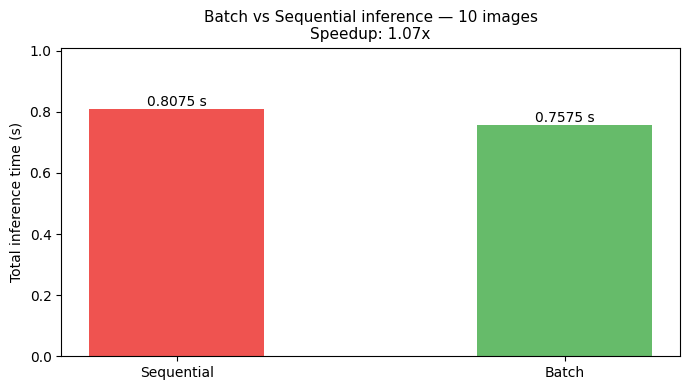

Saved: extra_batch.png


In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
modes = ["Sequential", "Batch"]
times = [single_time, batch_time]
bars  = ax.bar(modes, times, color=["#EF5350", "#66BB6A"], width=0.45)

for bar, t in zip(bars, times):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f"{t:.4f} s", ha="center", fontsize=10)

ax.set_title(f"Batch vs Sequential inference — {len(batch_urls)} images\nSpeedup: {speedup:.2f}x",
             fontsize=11)
ax.set_ylabel("Total inference time (s)")
ax.set_ylim(0, max(times) * 1.25)
plt.tight_layout()
plt.savefig("extra_batch.png", bbox_inches="tight", dpi=100)
plt.show()
print("Saved: extra_batch.png")

**Batch processing analysis:**

Batch inference is faster because PyTorch (and the underlying BLAS/cuDNN kernels) can exploit **data parallelism**: instead of N separate matrix multiplications, the entire batch is processed as one large tensor operation. On CPU this is less dramatic than on GPU, but still gives a measurable speedup due to:
- Reduced Python overhead (one `model()` call instead of N)
- Better memory access patterns (contiguous tensor)
- SIMD vectorization over the batch dimension

On a GPU the speedup would typically be 5–20× for a batch of 10, as the GPU's thousands of CUDA cores are fully utilised rather than sitting idle between single-image calls.